In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd


import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Number of Training Images:", X_train.shape[0])
print("Number of Testing Images:", X_test.shape[0])

print("Image Size:", X_train.shape[1], "x", X_train.shape[2])

Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)
Number of Training Images: 60000
Number of Testing Images: 10000
Image Size: 28 x 28


In [ ]:
class_names = [
    "T-shirt",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle Boot"
]

print(class_names)

['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle Boot']


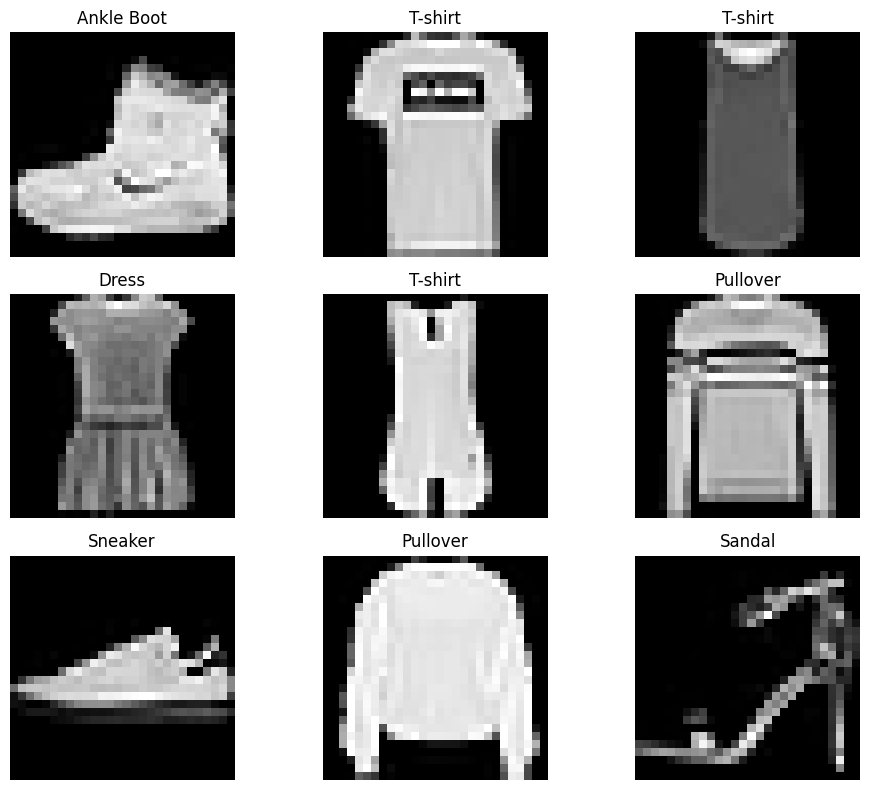

In [ ]:
plt.figure(figsize=(10,8))

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [ ]:
model = keras.Sequential([
    layers.Flatten(input_shape=(28,28)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8175 - loss: 0.5181 - val_accuracy: 0.8571 - val_loss: 0.3926
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8627 - loss: 0.3789 - val_accuracy: 0.8657 - val_loss: 0.3629
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8742 - loss: 0.3400 - val_accuracy: 0.8733 - val_loss: 0.3486
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8823 - loss: 0.3159 - val_accuracy: 0.8764 - val_loss: 0.3407
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8887 - loss: 0.2969 - val_accuracy: 0.8798 - val_loss: 0.3339
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8954 - loss: 0.2809 - val_accuracy: 0.8761 - val_loss: 0.3442
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9003 - loss: 0.2659 - val_accuracy: 0.8842 - val_loss: 0.3233
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9041 - loss: 0.2567 -

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8834 - loss: 0.3497
Test Loss: 0.3496529757976532
Test Accuracy: 0.883400022983551


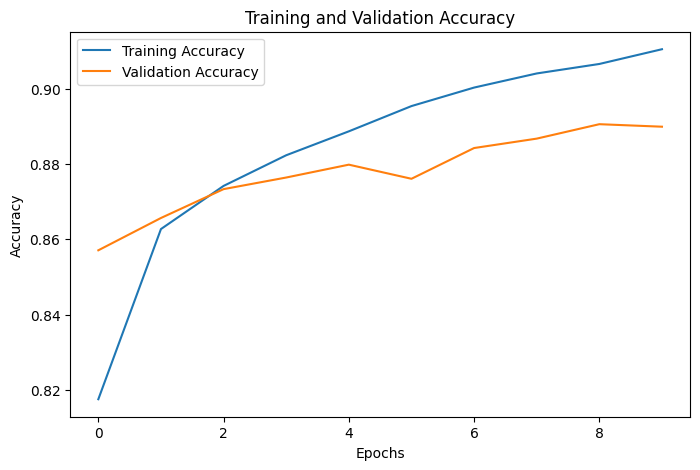

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.show()

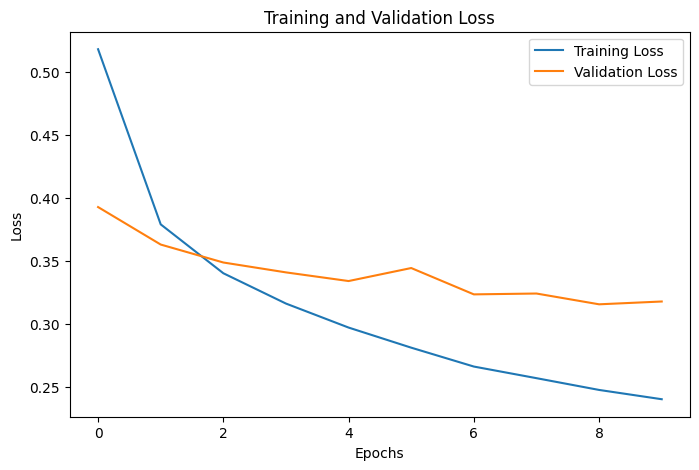

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.show()

In [ ]:
y_pred = model.predict(X_test)

y_pred_classes = np.argmax(y_pred, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


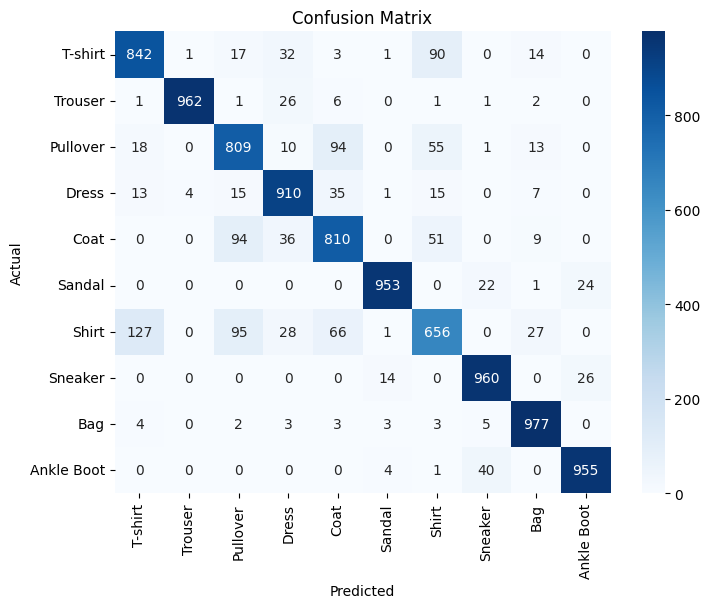

In [ ]:
cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
print(classification_report(
    y_test,
    y_pred_classes,
    target_names=class_names
))

              precision    recall  f1-score   support

     T-shirt       0.84      0.84      0.84      1000
     Trouser       0.99      0.96      0.98      1000
    Pullover       0.78      0.81      0.80      1000
       Dress       0.87      0.91      0.89      1000
        Coat       0.80      0.81      0.80      1000
      Sandal       0.98      0.95      0.96      1000
       Shirt       0.75      0.66      0.70      1000
     Sneaker       0.93      0.96      0.95      1000
         Bag       0.93      0.98      0.95      1000
  Ankle Boot       0.95      0.95      0.95      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



In [ ]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_classes
})

results.head(20)

,Actual,Predicted
0,9,9
1,2,2
2,1,1
3,1,1
4,6,6
5,1,1
6,4,4
7,6,6
8,5,5
9,7,7


In [ ]:
model_lr1 = keras.Sequential([
    layers.Flatten(input_shape=(28,28)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_lr1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.1),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_lr1 = model_lr1.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    verbose=0
)

print("Accuracy (LR=0.1):", history_lr1.history["val_accuracy"][-1])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Accuracy (LR=0.1): 0.09833333641290665


In [ ]:
model_lr2 = keras.Sequential([
    layers.Flatten(input_shape=(28,28)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_lr2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_lr2 = model_lr2.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    verbose=0
)

print("Accuracy (LR=0.01):", history_lr2.history["val_accuracy"][-1])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Accuracy (LR=0.01): 0.8534166812896729


In [ ]:
model_lr3 = keras.Sequential([
    layers.Flatten(input_shape=(28,28)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_lr3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_lr3 = model_lr3.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    verbose=0
)

print("Accuracy (LR=0.001):", history_lr3.history["val_accuracy"][-1])

Accuracy (LR=0.001): 0.8787500262260437


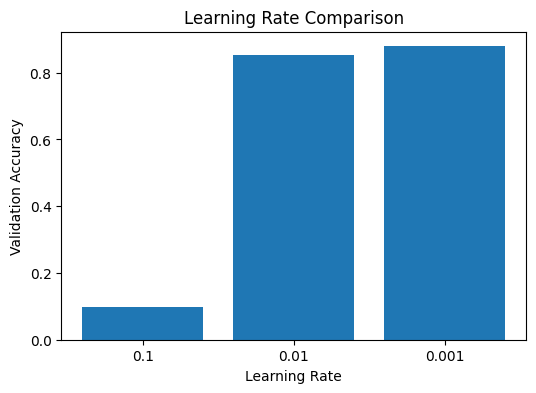

In [ ]:
learning_rates = ["0.1", "0.01", "0.001"]

accuracies = [
    history_lr1.history["val_accuracy"][-1],
    history_lr2.history["val_accuracy"][-1],
    history_lr3.history["val_accuracy"][-1]
]

plt.figure(figsize=(6,4))

plt.bar(learning_rates, accuracies)

plt.xlabel("Learning Rate")
plt.ylabel("Validation Accuracy")
plt.title("Learning Rate Comparison")

plt.show()

In [ ]:
model5 = keras.models.clone_model(model)
model5.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history5 = model5.fit(
    X_train,
    y_train,
    epochs=5,
    validation_split=0.2,
    verbose=0
)

print("Validation Accuracy (5 Epochs):", history5.history["val_accuracy"][-1])

Validation Accuracy (5 Epochs): 0.8738333582878113


In [ ]:
model10 = keras.models.clone_model(model)
model10.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history10 = model10.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    verbose=0
)

print("Validation Accuracy (10 Epochs):", history10.history["val_accuracy"][-1])

Validation Accuracy (10 Epochs): 0.8869166374206543


In [ ]:
model20 = keras.models.clone_model(model)
model20.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history20 = model20.fit(
    X_train,
    y_train,
    epochs=20,
    validation_split=0.2,
    verbose=0
)

print("Validation Accuracy (20 Epochs):", history20.history["val_accuracy"][-1])

Validation Accuracy (20 Epochs): 0.8911666870117188


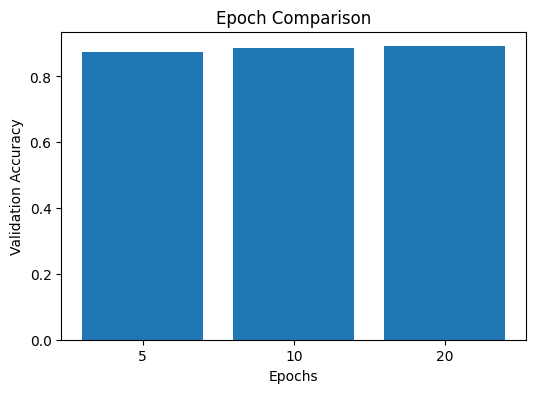

In [ ]:
epochs = ["5", "10", "20"]

accuracy = [
    history5.history["val_accuracy"][-1],
    history10.history["val_accuracy"][-1],
    history20.history["val_accuracy"][-1]
]

plt.figure(figsize=(6,4))

plt.bar(epochs, accuracy)

plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.title("Epoch Comparison")

plt.show()